# Predicción de bajo desempeño en Saber 11 — Cali

**Modelos MLP con registros de 2019, 2020 y 2022–2025**  
**Objetivo:** clasificar si el puntaje global de Saber 11 es inferior a **250 puntos**, utilizando características escolares, familiares y demográficas disponibles en los registros.

Este cuaderno reúne el flujo final de modelado, elimina exploraciones descartadas y separa **dos experimentos distintos**: división aleatoria (referencia) y evaluación temporal (prueba con 2025).

> **Alcance:** es una clasificación basada en datos históricos del examen, **no** una predicción validada con varios años de anticipación. Las alertas no reemplazan una evaluación educativa.

> **Reproducibilidad:** ejecutar desde la carpeta `scripts/` del proyecto, con el archivo limpio en `../data/processed/saber11_cali_2019_2025_limpio.csv`. La construcción original de este CSV se realizó en etapas exploratorias que se retiraron de esta versión para evitar código redundante. Se conserva el notebook original como respaldo de ese proceso.

**Modelos comparados:** MLP, Regresión Logística y Random Forest; además se evalúa un MLP con separación temporal.


## 1. Librerías y carga del dataset

Importamos todas las librerías una sola vez y cargamos el archivo limpio del proyecto. Las siguientes celdas reutilizan estos imports.

In [23]:
import os 
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

pd.set_option("display.max_columns", None)
ruta_csv = Path("../data/processed/saber11_cali_2019_2025_limpio.csv")
if not ruta_csv.exists():
    raise FileNotFoundError(f"Falta el dataset limpio: {ruta_csv}. Colócalo en data/processed/.")
df_saber11_final = pd.read_csv(ruta_csv)
print("Dimensiones:", df_saber11_final.shape)
display(df_saber11_final.head())

Dimensiones: (128260, 16)


,periodo,punt_global,edad_reportada,cole_jornada,cole_calendario,cole_naturaleza,cole_area_ubicacion,cole_bilingue,cole_caracter,fami_tieneinternet,fami_tienecomputador,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,estu_genero,edad
0,20191,313,1,MAÑANA,B,NO OFICIAL,URBANO,N,TÉCNICO,Si,No,Educación profesional incompleta,Secundaria (Bachillerato) completa,Estrato 3,M,17.765914
1,20191,339,1,COMPLETA,B,NO OFICIAL,URBANO,S,ACADÉMICO,Si,Si,Educación profesional completa,Educación profesional completa,Estrato 6,F,16.522930
2,20191,260,1,COMPLETA,B,NO OFICIAL,URBANO,N,ACADÉMICO,Si,Si,Técnica o tecnológica completa,Educación profesional completa,Estrato 6,M,17.555099
3,20191,257,1,COMPLETA,B,NO OFICIAL,URBANO,N,ACADÉMICO,No,Si,Educación profesional completa,Educación profesional completa,Estrato 5,M,16.884326
4,20191,280,1,MAÑANA,B,NO OFICIAL,URBANO,N,TÉCNICO,Si,Si,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) completa,Estrato 6,F,16.454483


## 2. Revisión de calidad y distribución

Comprobamos las columnas, el número de registros por año y los valores faltantes. Los datos disponibles corresponden a 2019, 2020 y 2022–2025; **no contamos con 2021**. La variable objetivo se construye directamente a partir de `punt_global` sin utilizar este puntaje como predictor.

In [2]:
columnas_necesarias = ["periodo", "punt_global", "edad", "cole_jornada", "cole_calendario",
 "cole_naturaleza", "cole_area_ubicacion", "cole_bilingue", "cole_caracter",
 "fami_tieneinternet", "fami_tienecomputador", "fami_educacionmadre",
 "fami_educacionpadre", "fami_estratovivienda", "estu_genero"]
faltan = sorted(set(columnas_necesarias) - set(df_saber11_final.columns))
assert not faltan, f"Faltan columnas: {faltan}"
assert df_saber11_final["punt_global"].notna().all(), "Hay puntajes globales faltantes; revisar la fuente."
df_modelo = df_saber11_final.copy()
df_modelo["anio"] = df_modelo["periodo"].astype(str).str[:4].astype(int)
df_modelo["bajo_desempeno"] = (df_modelo["punt_global"] < 250).astype(int)
print("Registros por año:")
display(df_modelo["anio"].value_counts().sort_index().rename("estudiantes"))
print("Clases (0: >=250; 1: <250):")
display(df_modelo["bajo_desempeno"].value_counts().sort_index())
print("Valores faltantes por columna:")
display(df_modelo[columnas_necesarias].isna().sum().sort_values(ascending=False))

Registros por año:


anio
2019    21788
2020    20030
2022    22289
2023    22290
2024    21099
2025    20764
Name: estudiantes, dtype: int64

Clases (0: >=250; 1: <250):


bajo_desempeno
0    73324
1    54936
Name: count, dtype: int64

Valores faltantes por columna:


edad                    1969
periodo                    0
punt_global                0
cole_jornada               0
cole_calendario            0
cole_naturaleza            0
cole_area_ubicacion        0
cole_bilingue              0
cole_caracter              0
fami_tieneinternet         0
fami_tienecomputador       0
fami_educacionmadre        0
fami_educacionpadre        0
fami_estratovivienda       0
estu_genero                0
dtype: int64

### 2.1. Distribución de la variable objetivo

Esta gráfica permite ver cuántos estudiantes están en cada clase. **Clase 1** significa puntaje inferior a 250; no implica un diagnóstico individual.

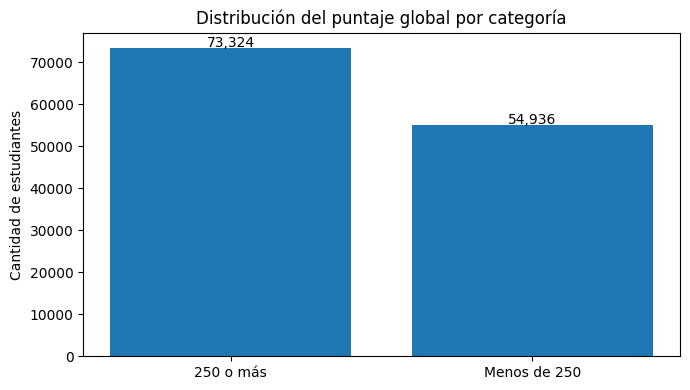

In [3]:
conteos = df_modelo["bajo_desempeno"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["250 o más", "Menos de 250"], conteos.values)
ax.set_title("Distribución del puntaje global por categoría")
ax.set_ylabel("Cantidad de estudiantes")
for i, valor in enumerate(conteos.values): ax.text(i, valor + 400, f"{valor:,}", ha="center")
plt.tight_layout(); plt.show()

## 3. Preparación de las 13 variables predictoras

Utilizamos **12 variables categóricas** sobre el colegio, el hogar y el estudiante, además del grupo de edad. Las edades decimales se interpretan como años cumplidos (por ejemplo, 17,8 pertenece al grupo 17). Las edades desconocidas y los valores categóricos ausentes se conservan como **`No reportado`**, sin inventar información.

In [4]:
variables_modelo = [
    "cole_jornada", "cole_calendario", "cole_naturaleza", "cole_area_ubicacion",
    "cole_bilingue", "cole_caracter", "fami_tieneinternet", "fami_tienecomputador",
    "fami_educacionmadre", "fami_educacionpadre", "fami_estratovivienda",
    "estu_genero", "grupo_edad"
]

def preparar_variables(datos):
    datos = datos.copy()
    edad = pd.to_numeric(datos["edad"], errors="coerce")
    condiciones = [edad < 16, (edad >= 16) & (edad < 17),
                   (edad >= 17) & (edad < 18), (edad >= 18) & (edad < 19),
                   (edad >= 19) & (edad < 20), (edad >= 20) & (edad < 25),
                   (edad >= 25) & (edad < 30), edad >= 30]
    etiquetas = ["15 o menos", "16", "17", "18", "19", "20 a 24", "25 a 29", "30 o más"]
    datos["grupo_edad"] = np.select(condiciones, etiquetas, default="No reportado")
    for columna in variables_modelo:
        datos[columna] = datos[columna].astype("string").fillna("No reportado")
    return datos

df_modelo = preparar_variables(df_modelo)
X = df_modelo[variables_modelo].copy()
y = df_modelo["bajo_desempeno"].copy()
print("Variables:", len(variables_modelo), "| Estudiantes:", len(X))
print("Edades no reportadas:", (df_modelo["grupo_edad"] == "No reportado").sum())
assert X.isna().sum().sum() == 0
print("Valores faltantes en predictores:", X.isna().sum().sum())

Variables: 13 | Estudiantes: 128260
Edades no reportadas: 1969
Valores faltantes en predictores: 0


## 4. Experimento A: MLP con división aleatoria

Se utiliza una separación estratificada 80/20 para tener una **referencia inicial**. El preprocesador aprende categorías solo del entrenamiento. Este experimento mezcla años entre entrenamiento y prueba, por lo que **no sirve por sí solo para evaluar generalización hacia años futuros**.

Dentro del 80 % de entrenamiento reservamos un 20 % adicional para validación y comparación justa entre algoritmos. El 20 % de prueba permanece aparte. El codificador se ajusta únicamente con el subconjunto de ajuste.


In [5]:
# ============================================
# DIVISIÓN DE DATOS: ENTRENAMIENTO Y PRUEBA
# ============================================


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("📊 DIVISIÓN DE DATOS")
print("=" * 55)

print("\n Total de estudiantes:", len(X))

print("\n Estudiantes para entrenamiento:", len(X_train))
print(" Estudiantes para prueba:", len(X_test))

print("\n Distribución en entrenamiento:")
print(y_train.value_counts(normalize=True).round(4) * 100)

print("\n Distribución en prueba:")
print(y_test.value_counts(normalize=True).round(4) * 100)

print("\n DATOS DIVIDIDOS CORRECTAMENTE")

# Validación común para comparar MLP, Regresión Logística y Random Forest.
# El conjunto de prueba (X_test) se mantiene separado de esta comparación.
X_train_ajuste, X_val_comparacion, y_train_ajuste, y_val_comparacion = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)
print("Ajuste de modelos:", X_train_ajuste.shape)
print("Validación de comparación:", X_val_comparacion.shape)


📊 DIVISIÓN DE DATOS

📌 Total de estudiantes: 128260

📌 Estudiantes para entrenamiento: 102608
📌 Estudiantes para prueba: 25652

📌 Distribución en entrenamiento:
bajo_desempeno
0    57.17
1    42.83
Name: proportion, dtype: float64

📌 Distribución en prueba:
bajo_desempeno
0    57.17
1    42.83
Name: proportion, dtype: float64

✅ DATOS DIVIDIDOS CORRECTAMENTE
Ajuste de modelos: (82086, 13)
Validación de comparación: (20522, 13)


In [6]:
# ============================================
# PREPROCESAMIENTO DE VARIABLES CATEGÓRICAS
# ============================================


# Todas las variables seleccionadas son categóricas
variables_categoricas = variables_modelo.copy()

# Crear el preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas
        )
    ]
)

# Aprender las categorías usando SOLO entrenamiento
X_train_procesado = preprocesador.fit_transform(X_train_ajuste)

# Transformar prueba sin volver a ajustar
X_val_comparacion_procesado = preprocesador.transform(X_val_comparacion)
X_test_procesado = preprocesador.transform(X_test)

print(" PREPROCESAMIENTO DE DATOS")
print("=" * 55)

print("\n Dimensiones originales:")
print("Entrenamiento:", X_train_ajuste.shape)
print("Validación:", X_val_comparacion.shape)
print("Prueba:", X_test.shape)

print("\n Dimensiones después de OneHotEncoder:")
print("Entrenamiento:", X_train_procesado.shape)
print("Validación:", X_val_comparacion_procesado.shape)
print("Prueba:", X_test_procesado.shape)

print("\n Valores faltantes después del procesamiento:")
print("Entrenamiento:", pd.isna(X_train_procesado).sum())
print("Prueba:", pd.isna(X_test_procesado).sum())

print("\n PREPROCESAMIENTO TERMINADO")

📊 PREPROCESAMIENTO DE DATOS

📌 Dimensiones originales:
Entrenamiento: (82086, 13)
Validación: (20522, 13)
Prueba: (25652, 13)

📌 Dimensiones después de OneHotEncoder:
Entrenamiento: (82086, 74)
Validación: (20522, 74)
Prueba: (25652, 74)

📌 Valores faltantes después del procesamiento:
Entrenamiento: 0
Prueba: 0

✅ PREPROCESAMIENTO TERMINADO


In [7]:
# ============================================
# CONSTRUCCIÓN DEL MODELO MLP
# ============================================


# Semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

# Crear red neuronal
modelo_mlp = keras.Sequential([
    layers.Input(shape=(X_train_procesado.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

# Compilar el modelo
modelo_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("ARQUITECTURA DEL MODELO MLP")
print("=" * 55)

modelo_mlp.summary()

print("\n MODELO MLP CONSTRUIDO CORRECTAMENTE")

🧠 ARQUITECTURA DEL MODELO MLP


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,913 (27.00 KB)

 Trainable params: 6,913 (27.00 KB)

 Non-trainable params: 0 (0.00 B)


✅ MODELO MLP CONSTRUIDO CORRECTAMENTE


In [8]:
# ============================================
# ENTRENAMIENTO DEL MODELO MLP
# ============================================


# Detener el entrenamiento si deja de mejorar
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print(" ENTRENAMIENTO DEL MODELO MLP")
print("=" * 55)

# Entrenar la red neuronal
historial = modelo_mlp.fit(
    X_train_procesado,
    y_train_ajuste,
    validation_data=(X_val_comparacion_procesado, y_val_comparacion),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\n ENTRENAMIENTO FINALIZADO")
print(" Épocas ejecutadas:", len(historial.history["loss"]))

🧠 ENTRENAMIENTO DEL MODELO MLP
Epoch 1/50
2566/2566 ━━━━━━━━━━━━━━━━━━━━ 2s 635us/step - accuracy: 0.6838 - auc: 0.7499 - loss: 0.5784 - precision: 0.6545 - recall: 0.5542 - val_accuracy: 0.6888 - val_auc: 0.7599 - val_loss: 0.5733 - val_precision: 0.6389 - val_recall: 0.6290
Epoch 2/50
2566/2566 ━━━━━━━━━━━━━━━━━━━━ 1s 533us/step - accuracy: 0.6912 - auc: 0.7606 - loss: 0.5693 - precision: 0.6621 - recall: 0.5698 - val_accuracy: 0.6895 - val_auc: 0.7610 - val_loss: 0.5730 - val_precision: 0.6326 - val_recall: 0.6557
Epoch 3/50
2566/2566 ━━━━━━━━━━━━━━━━━━━━ 1s 530us/step - accuracy: 0.6939 - auc: 0.7644 - loss: 0.5659 - precision: 0.6654 - recall: 0.5741 - val_accuracy: 0.6906 - val_auc: 0.7618 - val_loss: 0.5717 - val_precision: 0.6359 - val_recall: 0.6496
Epoch 4/50
2566/2566 ━━━━━━━━━━━━━━━━━━━━ 1s 526us/step - accuracy: 0.6967 - auc: 0.7672 - loss: 0.5634 - precision: 0.6686 - recall: 0.5787 - val_accuracy: 0.6912 - val_auc: 0.7617 - val_loss: 0.5713 - val_precision: 0.6388 - val_

### 4.1. Comparación con Regresión Logística y Random Forest

Además del MLP, probamos **Regresión Logística** y **Random Forest** para contar con modelos de referencia. Recuperamos del notebook original sus configuraciones: Regresión Logística con `max_iter=1000` y Random Forest con `n_estimators=100` y `max_depth=10`.

Los tres modelos utilizan **las mismas variables, el mismo preprocesamiento y los mismos registros de ajuste y validación**. Comparamos exactitud, precisión, sensibilidad (*recall*), F1 y AUC con un umbral de **0,50**. **No utilizamos los registros de prueba para elegir un modelo.** Las métricas se recalcularán al ejecutar el notebook; no copiamos resultados de experimentos antiguos que usaban otro conjunto de datos.

In [9]:
# Función para evaluar los tres modelos de la misma forma en validación.
def evaluar_modelo_comparacion(modelo, X_datos, y_real):
    if hasattr(modelo, "predict_proba"):
        probabilidades = modelo.predict_proba(X_datos)[:, 1]
    else:
        probabilidades = modelo.predict(X_datos, verbose=0).ravel()
    predicciones = (probabilidades >= 0.50).astype(int)
    return {
        "Exactitud": accuracy_score(y_real, predicciones),
        "Precisión": precision_score(y_real, predicciones, zero_division=0),
        "Sensibilidad": recall_score(y_real, predicciones, zero_division=0),
        "F1": f1_score(y_real, predicciones, zero_division=0),
        "AUC": roc_auc_score(y_real, probabilidades)
    }

# Configuraciones tomadas de las pruebas realizadas en el notebook original.
modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)
modelo_logistico.fit(X_train_procesado, y_train_ajuste)

modelo_rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
)
modelo_rf.fit(X_train_procesado, y_train_ajuste)

comparacion_modelos = pd.DataFrame({
    "MLP": evaluar_modelo_comparacion(modelo_mlp, X_val_comparacion_procesado, y_val_comparacion),
    "Regresión Logística": evaluar_modelo_comparacion(modelo_logistico, X_val_comparacion_procesado, y_val_comparacion),
    "Random Forest": evaluar_modelo_comparacion(modelo_rf, X_val_comparacion_procesado, y_val_comparacion)
}).T
print("COMPARACIÓN DE MODELOS EN VALIDACIÓN (UMBRAL 0,50)")
display(comparacion_modelos.round(4))

COMPARACIÓN DE MODELOS EN VALIDACIÓN (UMBRAL 0,50)


,Exactitud,Precisión,Sensibilidad,F1,AUC
MLP,0.6912,0.6388,0.6421,0.6404,0.7617
Regresión Logística,0.6920,0.6627,0.5721,0.6141,0.7565
Random Forest,0.6836,0.6639,0.5290,0.5888,0.7537


### 4.2. Visualización de la comparación

Esta gráfica facilita identificar las diferencias entre los tres modelos. **Un modelo no necesariamente es mejor en todas las métricas**: para detectar posibles casos de bajo desempeño nos interesa especialmente la sensibilidad, sin ignorar las falsas alertas reflejadas en la precisión. La elección del MLP también se estudia después mediante la evaluación temporal con 2025.

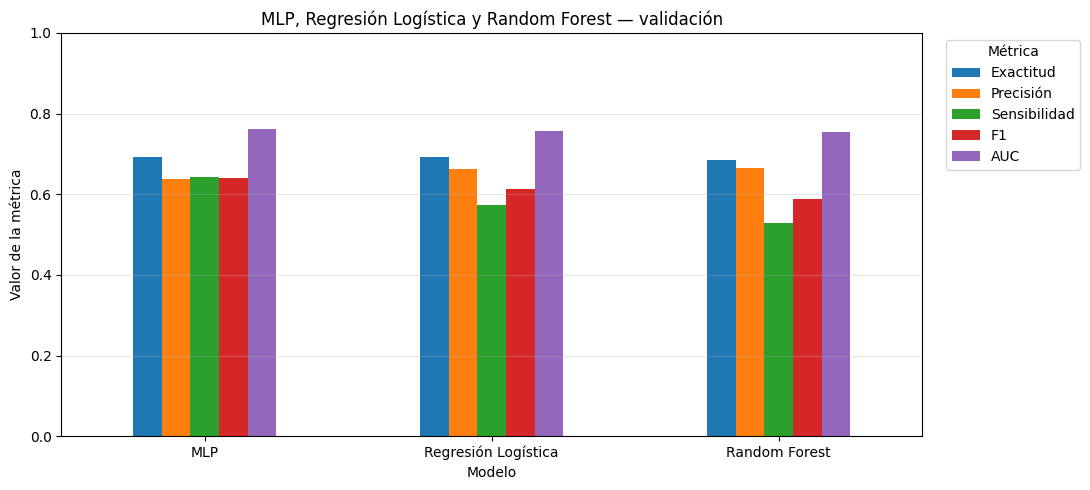

In [10]:
comparacion_modelos.plot(kind="bar", figsize=(11, 5), rot=0)
plt.title("MLP, Regresión Logística y Random Forest — validación")
plt.ylabel("Valor de la métrica")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Métrica", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.3. Curvas de entrenamiento y evaluación

Observamos la evolución de la pérdida y la exactitud y evaluamos con el conjunto aleatorio reservado. El umbral predeterminado de esta evaluación es 0,50.

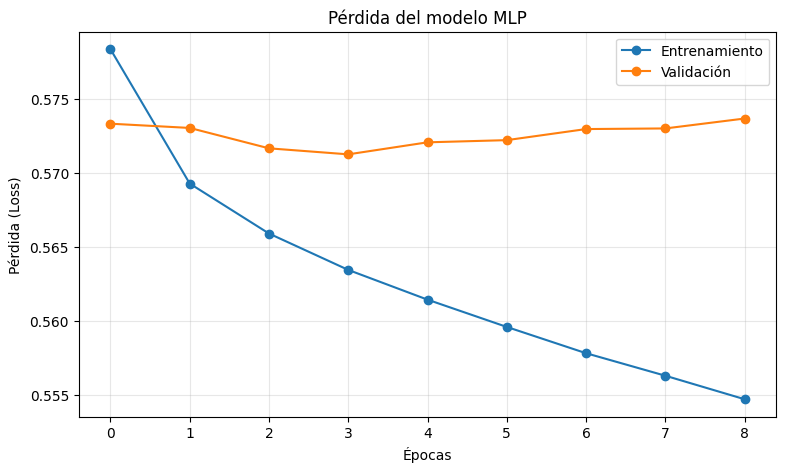

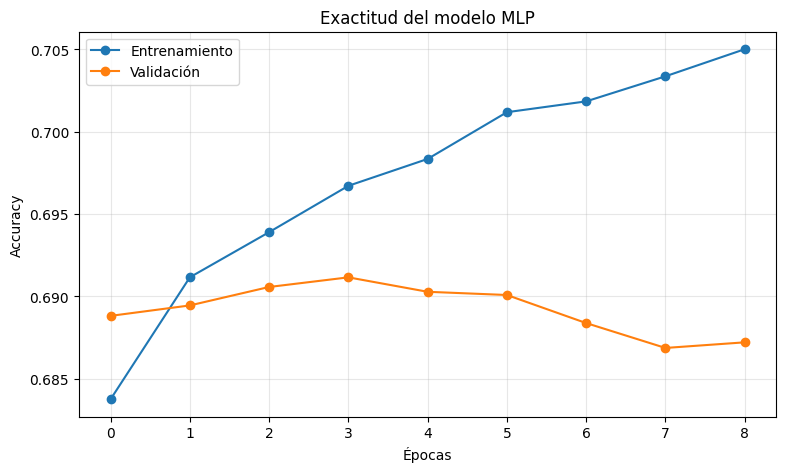

✅ GRÁFICAS GENERADAS CORRECTAMENTE


In [11]:
# ============================================
# GRÁFICAS DEL ENTRENAMIENTO DEL MODELO MLP
# ============================================


# Gráfica de pérdida
plt.figure(figsize=(9, 5))

plt.plot(
    historial.history["loss"],
    label="Entrenamiento",
    marker="o"
)

plt.plot(
    historial.history["val_loss"],
    label="Validación",
    marker="o"
)

plt.title("Pérdida del modelo MLP")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (Loss)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Gráfica de exactitud
plt.figure(figsize=(9, 5))

plt.plot(
    historial.history["accuracy"],
    label="Entrenamiento",
    marker="o"
)

plt.plot(
    historial.history["val_accuracy"],
    label="Validación",
    marker="o"
)

plt.title("Exactitud del modelo MLP")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(" GRÁFICAS GENERADAS CORRECTAMENTE")

In [12]:
# ============================================
# EVALUACIÓN DEL MODELO MLP
# ============================================

print(" EVALUACIÓN DEL MODELO MLP")
print("=" * 55)

# Evaluar el modelo con los datos de prueba
resultados = modelo_mlp.evaluate(
    X_test_procesado,
    y_test,
    verbose=0,
    return_dict=True
)

# Mostrar resultados
for metrica, valor in resultados.items():
    print(f" {metrica}: {valor:.4f}")

print("\n EVALUACIÓN TERMINADA")

📊 EVALUACIÓN DEL MODELO MLP
📌 accuracy: 0.6920
📌 auc: 0.7626
📌 loss: 0.5719
📌 precision: 0.6396
📌 recall: 0.6434

✅ EVALUACIÓN TERMINADA


In [13]:
probabilidades_aleatorio = modelo_mlp.predict(X_test_procesado, verbose=0).ravel()
print("AUC (prueba aleatoria):", round(roc_auc_score(y_test, probabilidades_aleatorio), 4))
print("Nota: el umbral 0.35 se exploró durante el desarrollo original; no fue seleccionado en validación independiente.")

AUC (prueba aleatoria): 0.7627
Nota: el umbral 0.35 se exploró durante el desarrollo original; no fue seleccionado en validación independiente.


## 5. Experimento B: evaluación temporal del MLP

Para comprobar el comportamiento con registros posteriores, se reservan **todos los registros de 2025 como prueba**. Los registros de 2019–2024 se dividen en entrenamiento y validación; esta última permite detener el aprendizaje y seleccionar el umbral **antes** de mirar el resultado de 2025.

> La validación dentro de 2019–2024 es aleatoria, aunque la prueba final es temporal. Este experimento tampoco demuestra una predicción anticipada desde cursos anteriores.

In [14]:
df_entrenamiento_temporal = df_modelo[df_modelo["anio"] < 2025].copy()
df_prueba_temporal = df_modelo[df_modelo["anio"] == 2025].copy()
X_train_temporal = df_entrenamiento_temporal[variables_modelo].copy()
y_train_temporal = df_entrenamiento_temporal["bajo_desempeno"].copy()
X_test_temporal = df_prueba_temporal[variables_modelo].copy()
y_test_temporal = df_prueba_temporal["bajo_desempeno"].copy()
print("2019–2024:", X_train_temporal.shape, "| 2025:", X_test_temporal.shape)
assert (df_entrenamiento_temporal["anio"] < 2025).all()
assert (df_prueba_temporal["anio"] == 2025).all()

2019–2024: (107496, 13) | 2025: (20764, 13)


### 5.1. Separar antes de ajustar OneHotEncoder

A diferencia de las pruebas exploratorias descartadas, primero dividimos entrenamiento y validación y **después** ajustamos `OneHotEncoder` solo con entrenamiento. El conjunto 2025 se transforma sin volver a ajustar el preprocesador.

In [15]:
# ============================================
# SEPARACIÓN CORRECTA ANTES DEL PREPROCESAMIENTO
# ============================================


print(" CORRECCIÓN DEL PREPROCESAMIENTO TEMPORAL")
print("=" * 60)

# 1. Separar los datos originales (antes de OneHotEncoder)
X_entreno_temp_final, X_validacion_temp_final, y_entreno_temp_final, y_validacion_temp_final = train_test_split(
    X_train_temporal,
    y_train_temporal,
    test_size=0.20,
    random_state=42,
    stratify=y_train_temporal
)

# 2. Crear un nuevo preprocesador
preprocesador_temporal_final = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_modelo
        )
    ]
)

# 3. Ajustar únicamente con los datos de entrenamiento
X_entreno_temp_procesado = preprocesador_temporal_final.fit_transform(
    X_entreno_temp_final
)

# 4. Transformar validación sin ajustar nuevamente
X_validacion_temp_procesado = preprocesador_temporal_final.transform(
    X_validacion_temp_final
)

# 5. Transformar 2025 sin ajustar nuevamente
X_test_temp_procesado = preprocesador_temporal_final.transform(
    X_test_temporal
)

# 6. Verificar resultados
print("\n Entrenamiento:", X_entreno_temp_procesado.shape)
print(" Validación:", X_validacion_temp_procesado.shape)
print(" Prueba 2025:", X_test_temp_procesado.shape)

print("\n Características generadas:")
print(X_entreno_temp_procesado.shape[1])

print("\n Valores faltantes:")
print("Entrenamiento:", np.isnan(X_entreno_temp_procesado).sum())
print("Validación:", np.isnan(X_validacion_temp_procesado).sum())
print("Prueba 2025:", np.isnan(X_test_temp_procesado).sum())

print("\n PREPROCESAMIENTO CORREGIDO")

🔧 CORRECCIÓN DEL PREPROCESAMIENTO TEMPORAL

📌 Entrenamiento: (85996, 72)
📌 Validación: (21500, 72)
📌 Prueba 2025: (20764, 72)

📌 Características generadas:
72

📌 Valores faltantes:
Entrenamiento: 0
Validación: 0
Prueba 2025: 0

✅ PREPROCESAMIENTO CORREGIDO


### 5.2. Entrenar la red neuronal temporal

La arquitectura es equivalente a la del primer experimento: dos capas ocultas de 64 y 32 neuronas y una salida sigmoide. `EarlyStopping` recupera los pesos de la época con menor pérdida de validación.

In [32]:
# ============================================
# ENTRENAMIENTO DEFINITIVO DEL MLP TEMPORAL
# ============================================


print(" ENTRENAMIENTO DEFINITIVO DEL MLP TEMPORAL")
print("=" * 60)

# Semilla para obtener resultados reproducibles
tf.keras.utils.set_random_seed(42)

# Crear el nuevo modelo
modelo_mlp_temporal_final = keras.Sequential([
    layers.Input(shape=(X_entreno_temp_procesado.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Compilar el modelo
modelo_mlp_temporal_final.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

# Configurar EarlyStopping
early_stopping_temporal_final = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Entrenar el modelo
historial_temporal_final = modelo_mlp_temporal_final.fit(
    X_entreno_temp_procesado,
    y_entreno_temp_final,
    validation_data=(
        X_validacion_temp_procesado,
        y_validacion_temp_final
    ),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping_temporal_final],
    verbose=1
)

print("\n ENTRENAMIENTO DEFINITIVO COMPLETADO")

print(
    " Épocas ejecutadas:",
    len(historial_temporal_final.history["loss"])
)

print(
    " Mejor pérdida de validación:",
    round(min(historial_temporal_final.history["val_loss"]), 4)
)

 ENTRENAMIENTO DEFINITIVO DEL MLP TEMPORAL
Epoch 1/50
2688/2688 ━━━━━━━━━━━━━━━━━━━━ 3s 678us/step - accuracy: 0.6815 - auc: 0.7507 - loss: 0.5793 - precision: 0.6541 - recall: 0.5627 - val_accuracy: 0.6918 - val_auc: 0.7658 - val_loss: 0.5661 - val_precision: 0.6517 - val_recall: 0.6205
Epoch 2/50
2642/2688 ━━━━━━━━━━━━━━━━━━━━ 0s 515us/step - accuracy: 0.6900 - auc: 0.7610 - loss: 0.5702 - precision: 0.6634 - recall: 0.5780

KeyboardInterrupt: 

### 5.3. Elegir el umbral usando solo validación

Se comparan los umbrales 0,30–0,50. Elegimos el de mayor F1 entre los valores probados y comprobamos su sensibilidad. La prueba 2025 permanece sin utilizar durante esta decisión.

In [31]:
# ============================================
# COMPARACIÓN FINAL DE UMBRALES EN VALIDACIÓN
# ============================================



print(" UMBRALES DEL MLP TEMPORAL DEFINITIVO")
print("=" * 60)

# Obtener probabilidades del conjunto de validación
probabilidades_validacion_final = (
    modelo_mlp_temporal_final.predict(
        X_validacion_temp_procesado,
        verbose=0
    ).ravel()
)

# Umbrales que vamos a comparar
umbrales_finales = [0.30, 0.35, 0.40, 0.45, 0.50]

resultados_umbrales_finales = []

for umbral in umbrales_finales:

    predicciones = (
        probabilidades_validacion_final >= umbral
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validacion_temp_final,
        predicciones
    ).ravel()

    resultados_umbrales_finales.append({
        "Umbral": umbral,
        "Accuracy (%)": round(
            accuracy_score(y_validacion_temp_final, predicciones) * 100, 2
        ),
        "Precisión (%)": round(
            precision_score(
                y_validacion_temp_final,
                predicciones,
                zero_division=0
            ) * 100, 2
        ),
        "Sensibilidad (%)": round(
            recall_score(
                y_validacion_temp_final,
                predicciones
            ) * 100, 2
        ),
        "F1-score (%)": round(
            f1_score(
                y_validacion_temp_final,
                predicciones
            ) * 100, 2
        ),
        "Falsos negativos": fn
    })

tabla_umbrales_finales = pd.DataFrame(
    resultados_umbrales_finales
)

print("\n RESULTADOS DE VALIDACIÓN:\n")

print(tabla_umbrales_finales.to_string(index=False))

# Seleccionar el umbral con mayor F1-score
mejor_resultado = tabla_umbrales_finales.loc[
    tabla_umbrales_finales["F1-score (%)"].idxmax()
]

umbral_temporal_final = float(mejor_resultado["Umbral"])

print("\n UMBRAL SELECCIONADO:", umbral_temporal_final)

print(
    " F1-score:",
    mejor_resultado["F1-score (%)"],
    "%"
)

print(
    " Sensibilidad:",
    mejor_resultado["Sensibilidad (%)"],
    "%"
)

print("\n UMBRAL DEL MODELO DEFINITIVO SELECCIONADO")

 UMBRALES DEL MLP TEMPORAL DEFINITIVO

 RESULTADOS DE VALIDACIÓN:

 Umbral  Accuracy (%)  Precisión (%)  Sensibilidad (%)  F1-score (%)  Falsos negativos
   0.30         62.60          54.13             89.87         67.57               944
   0.35         65.74          57.10             84.33         68.09              1460
   0.40         67.87          60.03             77.40         67.62              2106
   0.45         69.05          62.97             69.37         66.02              2854
   0.50         69.68          66.25             61.26         63.66              3610

 UMBRAL SELECCIONADO: 0.35
 F1-score: 68.09 %
 Sensibilidad: 84.33 %

 UMBRAL DEL MODELO DEFINITIVO SELECCIONADO


### 5.4. Evaluación final con 2025

Con el modelo y el umbral ya fijados, calculamos exactitud, precisión, sensibilidad, F1, AUC y matriz de confusión sobre **20.764 estudiantes de 2025**. No ajustamos el modelo a partir de estas métricas.

In [30]:
# ============================================
# EVALUACIÓN TEMPORAL FINAL - AÑO 2025
# ============================================



print(" EVALUACIÓN TEMPORAL DEL MODELO - 2025")
print("=" * 60)

# 1. Obtener probabilidades para estudiantes de 2025
probabilidades_2025 = modelo_mlp_temporal_final.predict(
    X_test_temp_procesado,
    verbose=0
).ravel()

# 2. Aplicar el umbral seleccionado en validación
predicciones_2025 = (
    probabilidades_2025 >= umbral_temporal_final
).astype(int)

# 3. Calcular métricas
accuracy_2025 = accuracy_score(
    y_test_temporal,
    predicciones_2025
)

precision_2025 = precision_score(
    y_test_temporal,
    predicciones_2025,
    zero_division=0
)

recall_2025 = recall_score(
    y_test_temporal,
    predicciones_2025
)

f1_2025 = f1_score(
    y_test_temporal,
    predicciones_2025
)

auc_2025 = roc_auc_score(
    y_test_temporal,
    probabilidades_2025
)

# 4. Matriz de confusión
matriz_2025 = confusion_matrix(
    y_test_temporal,
    predicciones_2025
)

tn, fp, fn, tp = matriz_2025.ravel()

# 5. Mostrar resultados
print("\n Estudiantes evaluados:", len(y_test_temporal))
print(" Año de evaluación: 2025")
print(" Umbral utilizado:", umbral_temporal_final)

print("\n MÉTRICAS DEL MODELO EN 2025")
print("-" * 45)

print(f"Accuracy:     {accuracy_2025 * 100:.2f}%")
print(f"Precisión:    {precision_2025 * 100:.2f}%")
print(f"Sensibilidad: {recall_2025 * 100:.2f}%")
print(f"F1-score:     {f1_2025 * 100:.2f}%")
print(f"AUC:          {auc_2025:.4f}")

print("\n MATRIZ DE CONFUSIÓN")
print(matriz_2025)

print("\n Interpretación de la matriz:")
print("Verdaderos negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdaderos positivos:", tp)

print("\n REPORTE DE CLASIFICACIÓN")
print(
    classification_report(
        y_test_temporal,
        predicciones_2025,
        target_names=[
            "Desempeño >= 250",
            "Bajo desempeño < 250"
        ],
        zero_division=0
    )
)

print("\n EVALUACIÓN TEMPORAL FINALIZADA")

 EVALUACIÓN TEMPORAL DEL MODELO - 2025

 Estudiantes evaluados: 20764
 Año de evaluación: 2025
 Umbral utilizado: 0.35

 MÉTRICAS DEL MODELO EN 2025
---------------------------------------------
Accuracy:     63.16%
Precisión:    52.58%
Sensibilidad: 84.87%
F1-score:     64.93%
AUC:          0.7532

 MATRIZ DE CONFUSIÓN
[[6032 6387]
 [1263 7082]]

 Interpretación de la matriz:
Verdaderos negativos: 6032
Falsos positivos: 6387
Falsos negativos: 1263
Verdaderos positivos: 7082

 REPORTE DE CLASIFICACIÓN
                      precision    recall  f1-score   support

    Desempeño >= 250       0.83      0.49      0.61     12419
Bajo desempeño < 250       0.53      0.85      0.65      8345

            accuracy                           0.63     20764
           macro avg       0.68      0.67      0.63     20764
        weighted avg       0.71      0.63      0.63     20764


 EVALUACIÓN TEMPORAL FINALIZADA


## 6. Visualización de los resultados temporales

La matriz de confusión distingue aciertos y errores. Las curvas permiten observar posibles señales de sobreajuste. La comparación validación–2025 muestra si las métricas se sostienen en el año posterior.

 MATRIZ DE CONFUSIÓN - EVALUACIÓN 2025


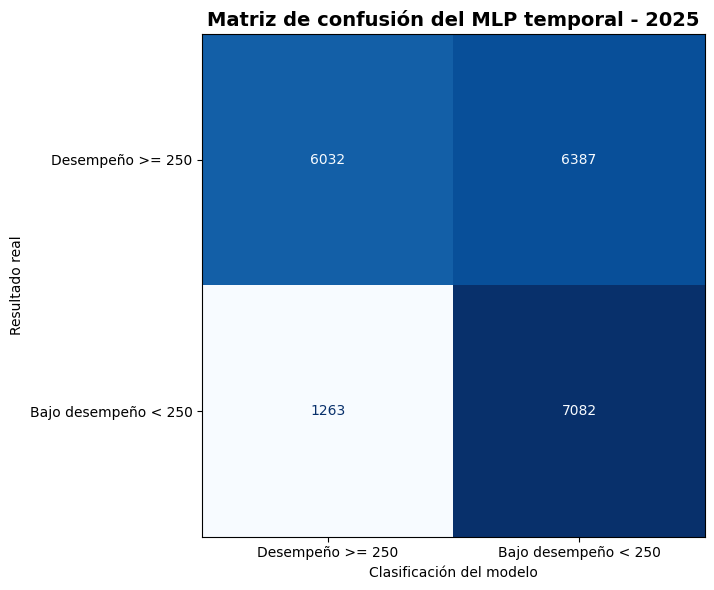


 Verdaderos negativos: 6032
 Falsos positivos: 6387
 Falsos negativos: 1263
 Verdaderos positivos: 7082

 MATRIZ DE CONFUSIÓN GENERADA


In [29]:
# ============================================
# MATRIZ DE CONFUSIÓN - MODELO TEMPORAL 2025
# ============================================


print(" MATRIZ DE CONFUSIÓN - EVALUACIÓN 2025")
print("=" * 55)

# Calcular matriz de confusión
matriz_temporal_2025 = confusion_matrix(
    y_test_temporal,
    predicciones_2025
)

# Crear gráfica
fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_temporal_2025,
    display_labels=[
        "Desempeño >= 250",
        "Bajo desempeño < 250"
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "Matriz de confusión del MLP temporal - 2025",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Clasificación del modelo")
plt.ylabel("Resultado real")

plt.tight_layout()
plt.show()

print("\n Verdaderos negativos:", matriz_temporal_2025[0, 0])
print(" Falsos positivos:", matriz_temporal_2025[0, 1])
print(" Falsos negativos:", matriz_temporal_2025[1, 0])
print(" Verdaderos positivos:", matriz_temporal_2025[1, 1])

print("\n MATRIZ DE CONFUSIÓN GENERADA")

📈 CURVAS DE APRENDIZAJE DEL MLP TEMPORAL


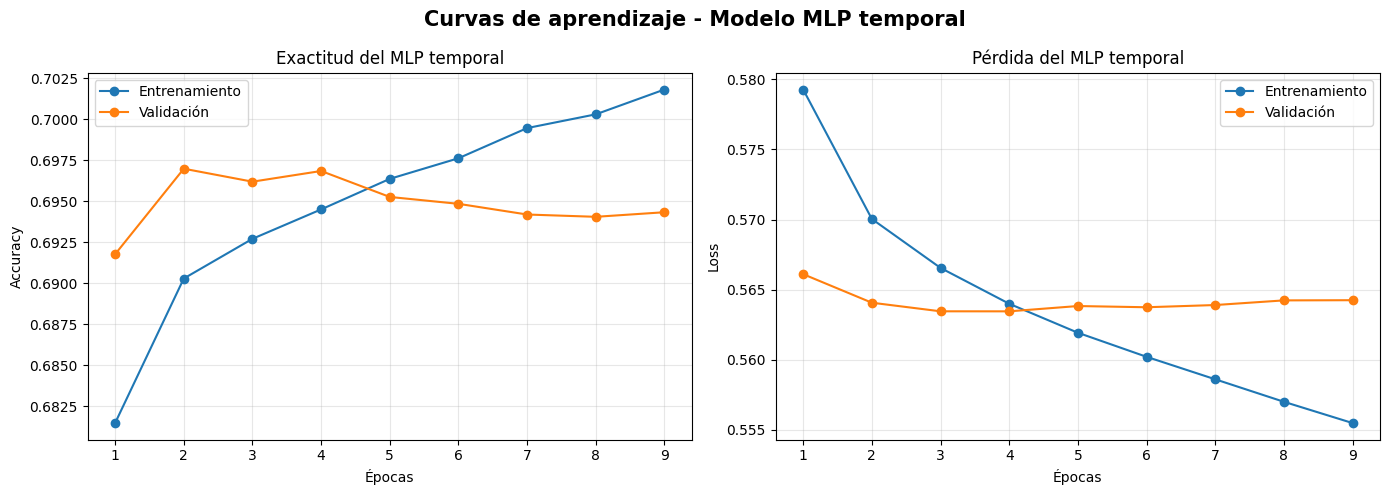


 Épocas ejecutadas: 9
 Mejor época según pérdida de validación: 4

 CURVAS DE APRENDIZAJE GENERADAS


In [28]:
# ============================================
# CURVAS DE APRENDIZAJE DEL MLP TEMPORAL
# ============================================


print(" CURVAS DE APRENDIZAJE DEL MLP TEMPORAL")
print("=" * 55)

# Obtener resultados del entrenamiento
historia = historial_temporal_final.history

epocas = range(1, len(historia["loss"]) + 1)

# Crear gráficas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Exactitud
axes[0].plot(
    epocas,
    historia["accuracy"],
    marker="o",
    label="Entrenamiento"
)

axes[0].plot(
    epocas,
    historia["val_accuracy"],
    marker="o",
    label="Validación"
)

axes[0].set_title("Exactitud del MLP temporal")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Gráfica 2: Pérdida
axes[1].plot(
    epocas,
    historia["loss"],
    marker="o",
    label="Entrenamiento"
)

axes[1].plot(
    epocas,
    historia["val_loss"],
    marker="o",
    label="Validación"
)

axes[1].set_title("Pérdida del MLP temporal")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Curvas de aprendizaje - Modelo MLP temporal",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\n Épocas ejecutadas:", len(historia["loss"]))

print(
    " Mejor época según pérdida de validación:",
    historia["val_loss"].index(
        min(historia["val_loss"])
    ) + 1
)

print("\n CURVAS DE APRENDIZAJE GENERADAS")

### 6.1. Comparación de métricas

Esta gráfica se calcula directamente a partir de las predicciones de validación y prueba, sin copiar porcentajes manualmente. Así sigue siendo válida si el entrenamiento cambia ligeramente entre ejecuciones.

,Métrica,Validación,Prueba 2025
0,Accuracy,65.74,63.16
1,Precisión,57.10,52.58
2,Sensibilidad,84.33,84.87
3,F1-score,68.09,64.93


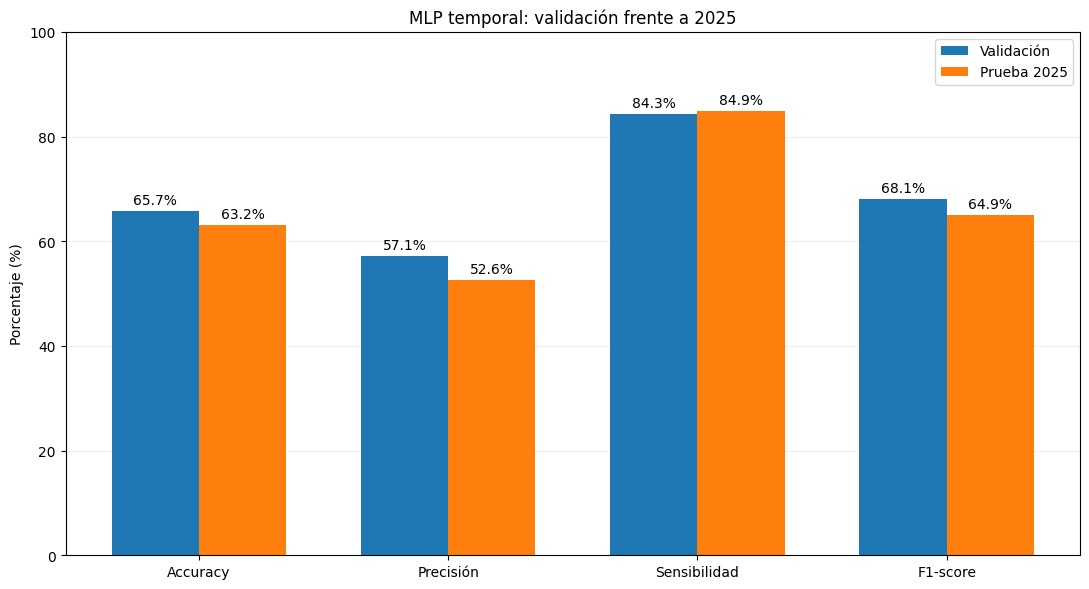

In [21]:
pred_validacion = (probabilidades_validacion_final >= umbral_temporal_final).astype(int)
metricas_comparacion = pd.DataFrame({
    "Métrica": ["Accuracy", "Precisión", "Sensibilidad", "F1-score"],
    "Validación": [accuracy_score(y_validacion_temp_final, pred_validacion)*100,
                   precision_score(y_validacion_temp_final, pred_validacion, zero_division=0)*100,
                   recall_score(y_validacion_temp_final, pred_validacion)*100,
                   f1_score(y_validacion_temp_final, pred_validacion)*100],
    "Prueba 2025": [accuracy_2025*100, precision_2025*100,
                    recall_2025*100, f1_2025*100]
})
display(metricas_comparacion.round(2))
x = np.arange(len(metricas_comparacion)); ancho = 0.35
fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x-ancho/2, metricas_comparacion["Validación"], ancho, label="Validación")
b2 = ax.bar(x+ancho/2, metricas_comparacion["Prueba 2025"], ancho, label="Prueba 2025")
ax.set_xticks(x, metricas_comparacion["Métrica"])
ax.set_ylim(0, 100); ax.set_ylabel("Porcentaje (%)")
ax.set_title("MLP temporal: validación frente a 2025")
ax.bar_label(b1, fmt="%.1f%%", padding=3)
ax.bar_label(b2, fmt="%.1f%%", padding=3)
ax.legend(); ax.grid(axis="y", alpha=0.2); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 7. Guardado y comprobación del modelo temporal

El modelo, el preprocesador y el umbral se guardan con nombres específicos para **no sobrescribir** los artefactos del modelo original que utiliza Streamlit.

In [27]:
# ============================================
# GUARDAR MODELO MLP TEMPORAL
# ============================================


print(" GUARDANDO MODELO MLP TEMPORAL")
print("=" * 55)

# Carpeta donde guardaremos los archivos
carpeta_modelos = "../modelos"

os.makedirs(carpeta_modelos, exist_ok=True)

# Rutas de los archivos
ruta_modelo = os.path.join(
    carpeta_modelos,
    "modelo_mlp_saber11_temporal_2025.keras"
)

ruta_preprocesador = os.path.join(
    carpeta_modelos,
    "preprocesador_saber11_temporal_2025.pkl"
)

ruta_umbral = os.path.join(
    carpeta_modelos,
    "umbral_saber11_temporal_2025.pkl"
)

# Guardar modelo
modelo_mlp_temporal_final.save(ruta_modelo)

# Guardar preprocesador
joblib.dump(
    preprocesador_temporal_final,
    ruta_preprocesador
)

# Guardar umbral
joblib.dump(
    umbral_temporal_final,
    ruta_umbral
)

# Verificar archivos
print("\n Archivos guardados:")

for ruta in [
    ruta_modelo,
    ruta_preprocesador,
    ruta_umbral
]:
    print(
        "✅" if os.path.exists(ruta) else "❌",
        ruta
    )

print("\n Umbral guardado:", umbral_temporal_final)

print("\n MODELO TEMPORAL GUARDADO CORRECTAMENTE")

 GUARDANDO MODELO MLP TEMPORAL

 Archivos guardados:
✅ ../modelos/modelo_mlp_saber11_temporal_2025.keras
✅ ../modelos/preprocesador_saber11_temporal_2025.pkl
✅ ../modelos/umbral_saber11_temporal_2025.pkl

 Umbral guardado: 0.35

 MODELO TEMPORAL GUARDADO CORRECTAMENTE


In [26]:
# ============================================
# VERIFICAR MODELO TEMPORAL GUARDADO
# ============================================


print(" VERIFICACIÓN DEL MODELO TEMPORAL")
print("=" * 55)

# Cargar los archivos guardados
modelo_temporal_cargado = keras.models.load_model(
    "../modelos/modelo_mlp_saber11_temporal_2025.keras"
)

preprocesador_temporal_cargado = joblib.load(
    "../modelos/preprocesador_saber11_temporal_2025.pkl"
)

umbral_temporal_cargado = joblib.load(
    "../modelos/umbral_saber11_temporal_2025.pkl"
)

print("\n Modelo cargado correctamente")
print(" Preprocesador cargado correctamente")
print(" Umbral cargado correctamente")

# Comprobar dimensiones
print("\n Entradas esperadas por el modelo:")
print(modelo_temporal_cargado.input_shape[1])

print("\n Características del preprocesador:")
print(
    len(preprocesador_temporal_cargado.get_feature_names_out())
)

print("\n Umbral:", umbral_temporal_cargado)

# Seleccionar cinco estudiantes de prueba
muestra = X_test_temporal.head(5)

# Aplicar el preprocesador cargado
muestra_procesada = preprocesador_temporal_cargado.transform(
    muestra
)

# Realizar predicciones
probabilidades = modelo_temporal_cargado.predict(
    muestra_procesada,
    verbose=0
).ravel()

predicciones = (
    probabilidades >= umbral_temporal_cargado
).astype(int)

print("\n PRUEBA CON CINCO ESTUDIANTES")

for i in range(len(probabilidades)):
    print(
        f"Estudiante {i + 1}: "
        f"Probabilidad = {probabilidades[i] * 100:.2f}% | "
        f"Clasificación = {predicciones[i]}"
    )

print("\n Interpretación:")
print("0 = Desempeño igual o superior a 250")
print("1 = Bajo desempeño (menos de 250)")

print("\n VERIFICACIÓN COMPLETADA")

 VERIFICACIÓN DEL MODELO TEMPORAL

 Modelo cargado correctamente
 Preprocesador cargado correctamente
 Umbral cargado correctamente

 Entradas esperadas por el modelo:
72

 Características del preprocesador:
72

 Umbral: 0.35

 PRUEBA CON CINCO ESTUDIANTES
Estudiante 1: Probabilidad = 0.42% | Clasificación = 0
Estudiante 2: Probabilidad = 8.09% | Clasificación = 0
Estudiante 3: Probabilidad = 19.45% | Clasificación = 0
Estudiante 4: Probabilidad = 43.16% | Clasificación = 1
Estudiante 5: Probabilidad = 22.30% | Clasificación = 0

 Interpretación:
0 = Desempeño igual o superior a 250
1 = Bajo desempeño (menos de 250)

✅ VERIFICACIÓN COMPLETADA


## 8. Conclusiones y limitaciones

### Resultados obtenidos en la ejecución documentada

La evaluación temporal se realizó sobre **20.764 estudiantes de 2025**, con umbral **0,35** seleccionado mediante validación. Se obtuvo:

| Métrica | Resultado en 2025 |
|---|---:|
| Exactitud | 63,16 % |
| Precisión | 52,58 % |
| Sensibilidad | **84,87 %** |
| F1-score | 64,93 % |
| AUC | 0,7532 |

El modelo identificó correctamente a **7.082** de los **8.345** estudiantes con puntaje inferior a 250. No identificó a **1.263** estudiantes de ese grupo y generó **6.387 falsas alertas**. Por tanto, logra una sensibilidad alta a costa de una precisión moderada.

Frente a la validación, la sensibilidad se mantuvo cercana al 85 %, mientras que la exactitud, la precisión y el F1 disminuyeron. La curva de pérdida muestra señales leves de sobreajuste después de la cuarta época, mitigadas mediante `EarlyStopping`.

### Limitaciones

- Las variables provienen de registros del Saber 11; **no se ha demostrado una alerta con varios años de anticipación**.
- El modelo produce numerosas falsas alertas. No debe utilizarse para etiquetar o tomar decisiones definitivas sobre estudiantes.
- El umbral se seleccionó entre un conjunto limitado de opciones y la salida sigmoide no fue calibrada como probabilidad.
- El experimento temporal usa validación aleatoria dentro de 2019–2024, aunque deja 2025 completamente reservado para prueba.
- El modelo de referencia con división aleatoria no se compara en condiciones idénticas con el temporal.

### Trabajo futuro

Obtener datos académicos **anteriores al examen**, validar con nuevas cohortes y mejorar la precisión sin perder demasiada sensibilidad. Esta versión se presenta como un **prototipo exploratorio de clasificación**.

### Comparación de algoritmos

La tabla de comparación de la sección 4 presenta los resultados **calculados en validación** para MLP, Regresión Logística y Random Forest. La evaluación temporal del MLP es un experimento distinto: no se deben comparar directamente sus métricas de 2025 con las de la validación aleatoria para declarar un ganador.
